In [ ]:
import os
import random
from pathlib import Path
from typing import Tuple, List, Dict, Optional

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.transforms.functional as TF


device: str = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
if device == "cuda":
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")

# (Reproducibility)
def seed_everything(seed: int = 42) -> None:
  
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(42)


class Config:
   
    
    DATASET_ROOT: Path = Path("/content/dataset/LEVIR-CD")

    
    IMG_SIZE: int = 256
    IN_CHANNELS: int = 3
    NUM_CLASSES: int = 2  # 0: No-Change, 1: Change
    BATCH_SIZE: int = 16
    NUM_WORKERS: int = 2

    
    BASE_LR: float = 1e-4
    WEIGHT_DECAY: float = 0.01
    BETAS: Tuple[float, float] = (0.9, 0.999)
    EPOCHS: int = 30

    
    SCALE_RANGE: Tuple[float, float] = (0.8, 1.2)

config = Config()
print("Configuration initialized successfully.")

Using device: cuda
GPU Name: Tesla T4
Configuration initialized successfully.


In [ ]:
import os
from google.colab import files


print("Please upload your kaggle.json file:")
uploaded = files.upload()

if "kaggle.json" not in uploaded:
    raise FileNotFoundError("kaggle.json not uploaded")


!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
print("Kaggle API token configured successfully!")


!mkdir -p /content/dataset
!kaggle datasets download -d mdrifaturrahman33/levir-cd -p /content/dataset
!unzip -q /content/dataset/levir-cd.zip -d /content/dataset/LEVIR-CD
!rm /content/dataset/levir-cd.zip

print("Dataset downloaded and extracted to /content/dataset/LEVIR-CD successfully!")

Please upload your kaggle.json file:


Saving kaggle.json to kaggle.json
Kaggle API token configured successfully!
Dataset URL: https://www.kaggle.com/datasets/mdrifaturrahman33/levir-cd
License(s): CC0-1.0
100% 2.30G/2.30G [00:13<00:00, 187MB/s]

Dataset downloaded and extracted to /content/dataset/LEVIR-CD successfully!


In [ ]:
import os
from pathlib import Path
from PIL import Image
import numpy as np

def inspect_dataset(root_path: Path) -> None:
    
    print(f"Inspecting directory: {root_path}\n" + "="*50)

    
    for root, dirs, files in os.walk(root_path):
        level = root.replace(str(root_path), '').count(os.sep)
        if level <= 3:
            indent = ' ' * 4 * level
            print(f"{indent}📁 {os.path.basename(root)}/ (Dirs: {len(dirs)}, Files: {len(files)})")

            
            image_files = [f for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg', '.tif'))]
            if image_files:
                sample_path = Path(root) / image_files[0]
                with Image.open(sample_path) as img:
                    arr = np.array(img)
                    unique_vals = np.unique(arr)
                    val_info = f"Unique values: {unique_vals}" if len(unique_vals) <= 10 else f"Min: {arr.min()}, Max: {arr.max()}"
                    print(f"{indent}    🔎 Sample: {image_files[0]} | Mode: {img.mode} | Size (W,H): {img.size} | Shape: {arr.shape} | {val_info}")

inspect_dataset(config.DATASET_ROOT)

Inspecting directory: /content/dataset/LEVIR-CD
📁 LEVIR-CD/ (Dirs: 1, Files: 0)
    📁 LEVIR CD/ (Dirs: 3, Files: 0)
        📁 val/ (Dirs: 3, Files: 0)
            📁 label/ (Dirs: 0, Files: 64)
                🔎 Sample: val_27.png | Mode: L | Size (W,H): (1024, 1024) | Shape: (1024, 1024) | Unique values: [  0 255]
            📁 A/ (Dirs: 0, Files: 64)
                🔎 Sample: val_27.png | Mode: RGB | Size (W,H): (1024, 1024) | Shape: (1024, 1024, 3) | Min: 0, Max: 255
            📁 B/ (Dirs: 0, Files: 64)
                🔎 Sample: val_27.png | Mode: RGB | Size (W,H): (1024, 1024) | Shape: (1024, 1024, 3) | Min: 0, Max: 255
        📁 train/ (Dirs: 3, Files: 0)
            📁 label/ (Dirs: 0, Files: 445)
                🔎 Sample: train_183.png | Mode: L | Size (W,H): (1024, 1024) | Shape: (1024, 1024) | Unique values: [0]
            📁 A/ (Dirs: 0, Files: 445)
                🔎 Sample: train_183.png | Mode: RGB | Size (W,H): (1024, 1024) | Shape: (1024, 1024, 3) | Min: 0, Max: 255
      

In [ ]:
import random
from pathlib import Path
from typing import Tuple, Dict, List
import numpy as np
from PIL import Image, ImageFilter

import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.transforms.functional as TF


config.DATASET_ROOT = Path("/content/dataset/LEVIR-CD/LEVIR CD")

class BiTemporalAugmentation:
  
    def __init__(
        self,
        crop_size: int = 256,
        scale_range: Tuple[float, float] = (0.8, 1.2),
        is_train: bool = True
    ) -> None:
        self.crop_size = crop_size
        self.scale_range = scale_range
        self.is_train = is_train

        # Standard ImageNet normalization
        self.imagenet_mean: List[float] = [0.485, 0.456, 0.406]
        self.imagenet_std: List[float] = [0.229, 0.224, 0.225]
        self.normalize = T.Normalize(mean=self.imagenet_mean, std=self.imagenet_std)

        # Photometric augmentation (Color Jittering)
        self.color_jitter = T.ColorJitter(
            brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1
        )

    def __call__(
        self, pre_img: Image.Image, post_img: Image.Image, label: Image.Image
    ) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        Applies identical spatial transformations to pre_img, post_img, and label
        to strictly preserve spatial co-registration.

        Args:
            pre_img: Pre-change PIL Image (RGB).
            post_img: Post-change PIL Image (RGB).
            label: Binary change mask PIL Image (L).

        Returns:
            Tuple of (pre_tensor, post_tensor, label_tensor).
        """
        if self.is_train:
            # 1. Random Horizontal Flip (Synchronized)
            if random.random() < 0.5:
                pre_img = TF.hflip(pre_img)
                post_img = TF.hflip(post_img)
                label = TF.hflip(label)

            # 2. Random Vertical Flip (Synchronized)
            if random.random() < 0.5:
                pre_img = TF.vflip(pre_img)
                post_img = TF.vflip(post_img)
                label = TF.vflip(label)

            # 3. Random Re-scale (0.8 to 1.2) + Synchronized Random Crop (256x256)
            scale = random.uniform(self.scale_range[0], self.scale_range[1])
            new_size = int(round(self.crop_size * scale))

            pre_img = TF.resize(pre_img, [new_size, new_size], interpolation=T.InterpolationMode.BILINEAR)
            post_img = TF.resize(post_img, [new_size, new_size], interpolation=T.InterpolationMode.BILINEAR)
            label = TF.resize(label, [new_size, new_size], interpolation=T.InterpolationMode.NEAREST)

            # Pad with zeros if scaled size is smaller than target crop_size (256)
            if new_size < self.crop_size:
                pad_val = self.crop_size - new_size
                pre_img = TF.pad(pre_img, padding=[0, 0, pad_val, pad_val], fill=0)
                post_img = TF.pad(post_img, padding=[0, 0, pad_val, pad_val], fill=0)
                label = TF.pad(label, padding=[0, 0, pad_val, pad_val], fill=0)

            # Extract identical Random Crop parameters for all three inputs
            i, j, h, w = T.RandomCrop.get_params(
                pre_img, output_size=(self.crop_size, self.crop_size)
            )
            pre_img = TF.crop(pre_img, i, j, h, w)
            post_img = TF.crop(post_img, i, j, h, w)
            label = TF.crop(label, i, j, h, w)

            # 4. Random Gaussian Blur
            if random.random() < 0.5:
                radius = random.uniform(0.1, 2.0)
                pre_img = pre_img.filter(ImageFilter.GaussianBlur(radius=radius))
                post_img = post_img.filter(ImageFilter.GaussianBlur(radius=radius))

            # 5. Random Color Jittering
            if random.random() < 0.5:
                pre_img = self.color_jitter(pre_img)
                post_img = self.color_jitter(post_img)
        else:
            # Ensure exact 256x256 size during Validation/Test
            if pre_img.size != (self.crop_size, self.crop_size):
                pre_img = TF.resize(pre_img, [self.crop_size, self.crop_size], interpolation=T.InterpolationMode.BILINEAR)
                post_img = TF.resize(post_img, [self.crop_size, self.crop_size], interpolation=T.InterpolationMode.BILINEAR)
                label = TF.resize(label, [self.crop_size, self.crop_size], interpolation=T.InterpolationMode.NEAREST)

        # Convert images to torch.float32 tensors in [0.0, 1.0] and apply ImageNet Normalization
        pre_tensor: torch.Tensor = TF.to_tensor(pre_img).to(torch.float32)   # Shape: [3, 256, 256]
        post_tensor: torch.Tensor = TF.to_tensor(post_img).to(torch.float32) # Shape: [3, 256, 256]

        pre_tensor = self.normalize(pre_tensor)   # Shape: [3, 256, 256]
        post_tensor = self.normalize(post_tensor) # Shape: [3, 256, 256]

        # Convert binary mask from [0, 255] to [0, 1] without channel dimension, dtype=torch.long
        label_np = np.array(label, dtype=np.uint8)              # Shape: [256, 256]
        label_binary = (label_np > 127).astype(np.int64)        # Shape: [256, 256], Values: {0, 1}
        label_tensor: torch.Tensor = torch.from_numpy(label_binary).to(torch.long)  # Shape: [256, 256]

        return pre_tensor, post_tensor, label_tensor

print("BiTemporalAugmentation initialized with ImageNet normalization.")

BiTemporalAugmentation initialized with ImageNet normalization.


In [ ]:
import os
import shutil
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
from tqdm.auto import tqdm

RAW_DATASET_ROOT = Path("/content/dataset/LEVIR-CD/LEVIR CD")
PATCH_DATASET_ROOT = Path("/content/dataset/LEVIR-CD-256")

def slice_and_save_patches(
    raw_root: Path,
    patch_root: Path,
    patch_size: int = 256,
    orig_size: int = 1024,
    remove_raw: bool = True
) -> None:
    """
    Slices 1024x1024 images into 256x256 non-overlapping patches once
    and saves them to fast local Colab storage to eliminate I/O bottlenecks.
    """
    if patch_root.exists() and any(patch_root.iterdir()):
        print(f"Pre-sliced dataset already exists at: {patch_root}")
        return

    grid_size = orig_size // patch_size
    splits = ["train", "val", "test"]

    for split in splits:
        raw_split_dir = raw_root / split
        out_split_dir = patch_root / split

        for sub in ["A", "B", "label"]:
            (out_split_dir / sub).mkdir(parents=True, exist_ok=True)

        file_names = sorted([
            f for f in os.listdir(raw_split_dir / "A")
            if f.lower().endswith(('.png', '.jpg', '.jpeg', '.tif'))
        ])

        def process_single_image(fname: str) -> None:
            stem = Path(fname).stem
            with Image.open(raw_split_dir / "A" / fname) as img_a, \
                 Image.open(raw_split_dir / "B" / fname) as img_b, \
                 Image.open(raw_split_dir / "label" / fname) as img_lbl:

                img_a = img_a.convert("RGB")
                img_b = img_b.convert("RGB")
                img_lbl = img_lbl.convert("L")

                for r in range(grid_size):
                    for c in range(grid_size):
                        top = r * patch_size
                        left = c * patch_size
                        box = (left, top, left + patch_size, top + patch_size)
                        patch_name = f"{stem}_r{r}_c{c}.png"

                        img_a.crop(box).save(out_split_dir / "A" / patch_name)
                        img_b.crop(box).save(out_split_dir / "B" / patch_name)
                        img_lbl.crop(box).save(out_split_dir / "label" / patch_name)

        print(f"Slicing '{split}' split ({len(file_names)} images -> {len(file_names) * 16} patches)...")
        with ThreadPoolExecutor(max_workers=4) as executor:
            list(tqdm(executor.map(process_single_image, file_names), total=len(file_names)))

    if remove_raw and raw_root.exists():
        shutil.rmtree(raw_root.parent)
        print("Removed raw 1024x1024 dataset to free up disk space.")

    print(f"All 256x256 patches successfully saved to: {patch_root}")


slice_and_save_patches(RAW_DATASET_ROOT, PATCH_DATASET_ROOT, patch_size=config.IMG_SIZE)
config.DATASET_ROOT = PATCH_DATASET_ROOT

Slicing 'train' split (445 images -> 7120 patches)...


  0%|          | 0/445 [00:00<?, ?it/s]

Slicing 'val' split (64 images -> 1024 patches)...


  0%|          | 0/64 [00:00<?, ?it/s]

Slicing 'test' split (128 images -> 2048 patches)...


  0%|          | 0/128 [00:00<?, ?it/s]

Removed raw 1024x1024 dataset to free up disk space.
All 256x256 patches successfully saved to: /content/dataset/LEVIR-CD-256


In [18]:
class FastLEVIRCDDataset(Dataset):
    """
    High-performance Dataset for pre-sliced 256x256 LEVIR-CD patches.
    Supports optional RAM caching (preload_to_ram=True) for zero disk I/O during training.
    """
    def __init__(
        self,
        root_dir: Path,
        split: str = "train",
        patch_size: int = 256,
        preload_to_ram: bool = True
    ) -> None:
        super().__init__()
        assert split in ["train", "val", "test"], f"Invalid split name: {split}"

        self.split_dir = root_dir / split
        self.pre_dir = self.split_dir / "A"
        self.post_dir = self.split_dir / "B"
        self.label_dir = self.split_dir / "label"
        self.preload_to_ram = preload_to_ram

        self.file_names: List[str] = sorted([
            f for f in os.listdir(self.pre_dir) if f.endswith('.png')
        ])

        self.augmentation = BiTemporalAugmentation(
            crop_size=patch_size,
            scale_range=config.SCALE_RANGE,
            is_train=(split == "train")
        )

        # Optional RAM cache storing compact uint8 numpy arrays
        self.ram_cache: List[Tuple[np.ndarray, np.ndarray, np.ndarray]] = []
        if self.preload_to_ram:
            print(f"Preloading {len(self.file_names)} patches for '{split}' into RAM...")
            for fname in tqdm(self.file_names, leave=False):
                with Image.open(self.pre_dir / fname) as pre_img, \
                     Image.open(self.post_dir / fname) as post_img, \
                     Image.open(self.label_dir / fname) as lbl_img:
                    self.ram_cache.append((
                        np.array(pre_img, dtype=np.uint8),
                        np.array(post_img, dtype=np.uint8),
                        np.array(lbl_img, dtype=np.uint8)
                    ))

    def __len__(self) -> int:
        """Returns total number of pre-sliced 256x256 patches."""
        return len(self.file_names)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        """
        Fetches a 256x256 patch pair from RAM (or fast SSD) and applies augmentations.

        Returns:
            Dict containing:
                - 'pre_image':  Tensor of shape [3, 256, 256], dtype=torch.float32
                - 'post_image': Tensor of shape [3, 256, 256], dtype=torch.float32
                - 'label':      Tensor of shape [256, 256], dtype=torch.long
        """
        if self.preload_to_ram:
            pre_np, post_np, lbl_np = self.ram_cache[idx]
            pre_patch = Image.fromarray(pre_np, mode="RGB")
            post_patch = Image.fromarray(post_np, mode="RGB")
            label_patch = Image.fromarray(lbl_np, mode="L")
        else:
            fname = self.file_names[idx]
            with Image.open(self.pre_dir / fname) as pre_img, \
                 Image.open(self.post_dir / fname) as post_img, \
                 Image.open(self.label_dir / fname) as lbl_img:
                pre_patch = pre_img.convert("RGB")
                post_patch = post_img.convert("RGB")
                label_patch = lbl_img.convert("L")

        pre_tensor, post_tensor, label_tensor = self.augmentation(
            pre_patch, post_patch, label_patch
        )

        return {
            'pre_image': pre_tensor,    # Shape: [3, 256, 256]
            'post_image': post_tensor,  # Shape: [3, 256, 256]
            'label': label_tensor       # Shape: [256, 256]
        }


# Instantiate Fast Datasets (Cached in RAM for maximum throughput)
train_dataset = FastLEVIRCDDataset(root_dir=config.DATASET_ROOT, split="train", preload_to_ram=True)
val_dataset = FastLEVIRCDDataset(root_dir=config.DATASET_ROOT, split="val", preload_to_ram=True)
test_dataset = FastLEVIRCDDataset(root_dir=config.DATASET_ROOT, split="test", preload_to_ram=True)

# Instantiate DataLoaders (Batch Size = 16 for Train, 32 for faster Val/Test inference)
train_loader = DataLoader(
    train_dataset,
    batch_size=config.BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=config.BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=config.BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# Verify DataLoader & Shape Contract
batch = next(iter(train_loader))
pre_batch = batch['pre_image']
post_batch = batch['post_image']
label_batch = batch['label']

print(f"\nTotal patches -> Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")
print("-" * 65)
print(f"Key 'pre_image'  | Shape: {list(pre_batch.shape)}  | Dtype: {pre_batch.dtype}")
print(f"Key 'post_image' | Shape: {list(post_batch.shape)}  | Dtype: {post_batch.dtype}")
print(f"Key 'label'      | Shape: {list(label_batch.shape)}      | Dtype: {label_batch.dtype} | Classes: {torch.unique(label_batch).tolist()}")

# Strict Contract Assertions
assert pre_batch.shape == (16, 3, 256, 256) and pre_batch.dtype == torch.float32
assert post_batch.shape == (16, 3, 256, 256) and post_batch.dtype == torch.float32
assert label_batch.shape == (16, 256, 256) and label_batch.dtype == torch.long
print("-" * 65)
print("Fast RAM-Cached DataLoader & Shape Contracts verified successfully!")

Preloading 7120 patches for 'train' into RAM...


  0%|          | 0/7120 [00:00<?, ?it/s]

Preloading 1024 patches for 'val' into RAM...


  0%|          | 0/1024 [00:00<?, ?it/s]

Preloading 2048 patches for 'test' into RAM...


  0%|          | 0/2048 [00:00<?, ?it/s]

/tmp/ipykernel_480/1253263909.py:62: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pre_patch = Image.fromarray(pre_np, mode="RGB")
/tmp/ipykernel_480/1253263909.py:63: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  post_patch = Image.fromarray(post_np, mode="RGB")
/tmp/ipykernel_480/1253263909.py:64: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  label_patch = Image.fromarray(lbl_np, mode="L")



Total patches -> Train: 7120 | Val: 1024 | Test: 2048
-----------------------------------------------------------------
Key 'pre_image'  | Shape: [16, 3, 256, 256]  | Dtype: torch.float32
Key 'post_image' | Shape: [16, 3, 256, 256]  | Dtype: torch.float32
Key 'label'      | Shape: [16, 256, 256]      | Dtype: torch.int64 | Classes: [0, 1]
-----------------------------------------------------------------
Fast RAM-Cached DataLoader & Shape Contracts verified successfully!


In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from typing import List, Tuple


class DownsamplingBlock(nn.Module):
    """
    Hierarchical Downsampling Block (Overlap Patch Merging).
    Reduces spatial resolution while increasing channel dimension.
    - Stage 1: Conv2d(K=7, S=4, P=3) -> H/4, W/4
    - Stage 2-4: Conv2d(K=3, S=2, P=1) -> H/2, W/2
    """
    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        kernel_size: int = 3,
        stride: int = 2,
        padding: int = 1
    ) -> None:
        super().__init__()
        self.proj = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding
        )
        self.norm = nn.LayerNorm(out_channels)

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, int, int]:
        """
        Args:
            x: Input spatial tensor of shape [B, C_in, H_in, W_in].

        Returns:
            out: Spatial tensor of shape [B, C_out, H_out, W_out].
            H_out: Output height.
            W_out: Output width.
        """
        x = self.proj(x)                        # Shape: [B, C_out, H_out, W_out]
        B, C, H, W = x.shape

        # Flatten spatial dimensions for LayerNorm, then restore spatial format
        x_seq = x.flatten(2).permute(0, 2, 1)   # Shape: [B, H_out * W_out, C_out]
        x_seq = self.norm(x_seq)                # Shape: [B, H_out * W_out, C_out]
        out = x_seq.permute(0, 2, 1).reshape(B, C, H, W)  # Shape: [B, C_out, H_out, W_out]

        return out, H, W


class SequenceReductionAttention(nn.Module):
    """
    Multi-Head Self-Attention with Sequence Reduction (SR-MHSA).
    Reduces computational complexity from O((HW)^2) to O((HW)^2 / R) by reshaping
    the sequence of length N = H*W into (N / R, C * R) followed by a Linear projection.
    """
    def __init__(
        self,
        dim: int,
        num_heads: int = 1,
        reduction_ratio: int = 1,
        attn_drop: float = 0.0,
        proj_drop: float = 0.0
    ) -> None:
        super().__init__()
        assert dim % num_heads == 0, f"dim ({dim}) must be divisible by num_heads ({num_heads})."
        self.dim = dim
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.reduction_ratio = reduction_ratio

        self.q = nn.Linear(dim, dim)
        self.kv = nn.Linear(dim, dim * 2)
        self.attn_drop = nn.Dropout(attn_drop)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)

        if self.reduction_ratio > 1:
            self.sr_linear = nn.Linear(dim * reduction_ratio, dim)
            self.sr_norm = nn.LayerNorm(dim)

    def forward(self, x: torch.Tensor, H: int, W: int) -> torch.Tensor:
        """
        Args:
            x: Flattened sequence tensor of shape [B, N, C] where N = H * W.
            H: Spatial height at current stage.
            W: Spatial width at current stage.

        Returns:
            Output sequence tensor of shape [B, N, C].
        """
        B, N, C = x.shape                                   # Shape: [B, H*W, C]

        # 1. Compute Query from full-resolution sequence
        q = self.q(x).reshape(B, N, self.num_heads, self.head_dim).permute(0, 2, 1, 3)
        # q Shape: [B, num_heads, N, head_dim]

        # 2. Apply Sequence Reduction (R) before computing Key and Value
        if self.reduction_ratio > 1:
            # Reshape sequence from [B, N, C] to [B, N // R, C * R]
            n_reduced = N // self.reduction_ratio
            x_reduced = x.reshape(B, n_reduced, C * self.reduction_ratio)  # Shape: [B, HW/R, C*R]
            x_reduced = self.sr_linear(x_reduced)                          # Shape: [B, HW/R, C]
            x_reduced = self.sr_norm(x_reduced)                            # Shape: [B, HW/R, C]
        else:
            x_reduced = x                                                  # Shape: [B, HW, C]

        kv = self.kv(x_reduced).reshape(B, -1, 2, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        k, v = kv[0], kv[1]                                 # k, v Shape: [B, num_heads, HW/R, head_dim]

        # 3. Scaled Dot-Product Attention
        attn = (q @ k.transpose(-2, -1)) * self.scale       # Shape: [B, num_heads, N, HW/R]
        attn = attn.softmax(dim=-1)                         # Shape: [B, num_heads, N, HW/R]
        attn = self.attn_drop(attn)

        out = (attn @ v).transpose(1, 2).reshape(B, N, C)   # Shape: [B, N, C]
        out = self.proj(out)                                # Shape: [B, N, C]
        out = self.proj_drop(out)                           # Shape: [B, N, C]

        return out


class DynamicPositionalEncodingFFN(nn.Module):
    """
    Dynamic Positional Encoding Feed-Forward Network.
    Formula: F_out = MLP(GELU(Conv2D_3x3(MLP(F_in)))) + F_in
    Uses 3x3 Depth-wise Convolution (groups = channels) to inject dynamic spatial context.
    """
    def __init__(
        self,
        in_features: int,
        hidden_features: int,
        drop: float = 0.0
    ) -> None:
        super().__init__()
        self.mlp1 = nn.Linear(in_features, hidden_features)
        self.dwconv = nn.Conv2d(
            hidden_features,
            hidden_features,
            kernel_size=3,
            stride=1,
            padding=1,
            groups=hidden_features
        )
        self.act = nn.GELU()
        self.mlp2 = nn.Linear(hidden_features, in_features)
        self.drop = nn.Dropout(drop)

    def forward(self, x: torch.Tensor, H: int, W: int) -> torch.Tensor:
        """
        Args:
            x: Input sequence tensor F_in of shape [B, N, C] where N = H * W.
            H: Spatial height.
            W: Spatial width.

        Returns:
            Output sequence tensor F_out of shape [B, N, C].
        """
        B, N, C = x.shape                                   # Shape: [B, H*W, C]
        shortcut = x                                        # Save F_in for Residual Skip Connection

        # Step 1: First MLP projection
        x = self.mlp1(x)                                    # Shape: [B, H*W, C_hidden]
        C_hidden = x.shape[-1]

        # Step 2: Reshape to 2D spatial format [B, C_hidden, H, W] for 3x3 Depth-wise Conv
        x_spatial = x.permute(0, 2, 1).reshape(B, C_hidden, H, W)  # Shape: [B, C_hidden, H, W]
        x_spatial = self.dwconv(x_spatial)                         # Shape: [B, C_hidden, H, W]

        # Step 3: Flatten back to sequence [B, H*W, C_hidden] and apply GELU
        x = x_spatial.flatten(2).permute(0, 2, 1)           # Shape: [B, H*W, C_hidden]
        x = self.act(x)                                     # Shape: [B, H*W, C_hidden]
        x = self.drop(x)

        # Step 4: Second MLP projection + Residual Addition (+ F_in)
        x = self.mlp2(x)                                    # Shape: [B, H*W, C]
        x = self.drop(x)
        out = x + shortcut                                  # Shape: [B, H*W, C]

        return out


class TransformerBlock(nn.Module):
    """
    Core Transformer Block combining Sequence Reduction Multi-Head Self-Attention
    and Dynamic Positional Encoding FFN.
    """
    def __init__(
        self,
        dim: int,
        num_heads: int,
        reduction_ratio: int = 1,
        mlp_ratio: int = 4,
        drop: float = 0.0,
        attn_drop: float = 0.0
    ) -> None:
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = SequenceReductionAttention(
            dim=dim,
            num_heads=num_heads,
            reduction_ratio=reduction_ratio,
            attn_drop=attn_drop,
            proj_drop=drop
        )
        self.norm2 = nn.LayerNorm(dim)
        self.pos_ffn = DynamicPositionalEncodingFFN(
            in_features=dim,
            hidden_features=dim * mlp_ratio,
            drop=drop
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: Spatial feature tensor of shape [B, C, H, W].

        Returns:
            Spatial feature tensor of shape [B, C, H, W].
        """
        B, C, H, W = x.shape                                # Shape: [B, C, H, W]

        # Convert 2D spatial map [B, C, H, W] to sequence [B, H*W, C]
        x_seq = x.flatten(2).permute(0, 2, 1)               # Shape: [B, H*W, C]

        # Attention sub-block with residual connection
        x_seq = x_seq + self.attn(self.norm1(x_seq), H, W)  # Shape: [B, H*W, C]

        # Dynamic Positional Encoding FFN (contains internal + F_in residual connection)
        x_seq = self.pos_ffn(self.norm2(x_seq), H, W)       # Shape: [B, H*W, C]

        # Restore 2D spatial format [B, C, H, W]
        out = x_seq.permute(0, 2, 1).reshape(B, C, H, W)    # Shape: [B, C, H, W]

        return out

print("DownsamplingBlock and TransformerBlock modules defined successfully.")

DownsamplingBlock and TransformerBlock modules defined successfully.


In [9]:
class HierarchicalTransformerEncoder(nn.Module):
    """
    4-Stage Hierarchical Transformer Encoder.
    Extracts multi-scale feature maps at resolutions [H/4, H/8, H/16, H/32].
    """
    def __init__(
        self,
        in_channels: int = 3,
        embed_dims: List[int] = [64, 128, 320, 512],
        num_heads: List[int] = [1, 2, 5, 8],
        reduction_ratios: List[int] = [64, 16, 4, 1],
        depths: List[int] = [2, 2, 2, 2],
        mlp_ratio: int = 4,
        drop_rate: float = 0.0
    ) -> None:
        super().__init__()
        self.num_stages = 4

        # Stage 1: Initial Downsampling (K=7, S=4, P=3) + Transformer Blocks
        self.downsample1 = DownsamplingBlock(
            in_channels=in_channels, out_channels=embed_dims[0],
            kernel_size=7, stride=4, padding=3
        )
        self.stage1 = nn.ModuleList([
            TransformerBlock(
                dim=embed_dims[0], num_heads=num_heads[0],
                reduction_ratio=reduction_ratios[0], mlp_ratio=mlp_ratio, drop=drop_rate
            ) for _ in range(depths[0])
        ])
        self.norm1 = nn.LayerNorm(embed_dims[0])

        # Stage 2: Downsampling (K=3, S=2, P=1) + Transformer Blocks
        self.downsample2 = DownsamplingBlock(
            in_channels=embed_dims[0], out_channels=embed_dims[1],
            kernel_size=3, stride=2, padding=1
        )
        self.stage2 = nn.ModuleList([
            TransformerBlock(
                dim=embed_dims[1], num_heads=num_heads[1],
                reduction_ratio=reduction_ratios[1], mlp_ratio=mlp_ratio, drop=drop_rate
            ) for _ in range(depths[1])
        ])
        self.norm2 = nn.LayerNorm(embed_dims[1])

        # Stage 3: Downsampling (K=3, S=2, P=1) + Transformer Blocks
        self.downsample3 = DownsamplingBlock(
            in_channels=embed_dims[1], out_channels=embed_dims[2],
            kernel_size=3, stride=2, padding=1
        )
        self.stage3 = nn.ModuleList([
            TransformerBlock(
                dim=embed_dims[2], num_heads=num_heads[2],
                reduction_ratio=reduction_ratios[2], mlp_ratio=mlp_ratio, drop=drop_rate
            ) for _ in range(depths[2])
        ])
        self.norm3 = nn.LayerNorm(embed_dims[2])

        # Stage 4: Downsampling (K=3, S=2, P=1) + Transformer Blocks
        self.downsample4 = DownsamplingBlock(
            in_channels=embed_dims[2], out_channels=embed_dims[3],
            kernel_size=3, stride=2, padding=1
        )
        self.stage4 = nn.ModuleList([
            TransformerBlock(
                dim=embed_dims[3], num_heads=num_heads[3],
                reduction_ratio=reduction_ratios[3], mlp_ratio=mlp_ratio, drop=drop_rate
            ) for _ in range(depths[3])
        ])
        self.norm4 = nn.LayerNorm(embed_dims[3])

    def _apply_stage_norm(self, x: torch.Tensor, norm_layer: nn.LayerNorm) -> torch.Tensor:
        """Helper to apply LayerNorm over channel dim of a [B, C, H, W] tensor."""
        B, C, H, W = x.shape
        x = x.flatten(2).permute(0, 2, 1)                   # Shape: [B, H*W, C]
        x = norm_layer(x)                                   # Shape: [B, H*W, C]
        return x.permute(0, 2, 1).reshape(B, C, H, W)       # Shape: [B, C, H, W]

    def forward(self, x: torch.Tensor) -> List[torch.Tensor]:
        """
        Args:
            x: Input RGB image tensor of shape [B, 3, 256, 256].

        Returns:
            List of 4 multi-scale feature tensors:
                - f1: [B, 64, 64, 64]
                - f2: [B, 128, 32, 32]
                - f3: [B, 320, 16, 16]
                - f4: [B, 512, 8, 8]
        """
        # Stage 1
        x, _, _ = self.downsample1(x)                       # Shape: [B, 64, 64, 64]
        for blk in self.stage1:
            x = blk(x)                                      # Shape: [B, 64, 64, 64]
        f1 = self._apply_stage_norm(x, self.norm1)          # Shape: [B, 64, 64, 64]

        # Stage 2
        x, _, _ = self.downsample2(f1)                      # Shape: [B, 128, 32, 32]
        for blk in self.stage2:
            x = blk(x)                                      # Shape: [B, 128, 32, 32]
        f2 = self._apply_stage_norm(x, self.norm2)          # Shape: [B, 128, 32, 32]

        # Stage 3
        x, _, _ = self.downsample3(f2)                      # Shape: [B, 320, 16, 16]
        for blk in self.stage3:
            x = blk(x)                                      # Shape: [B, 320, 16, 16]
        f3 = self._apply_stage_norm(x, self.norm3)          # Shape: [B, 320, 16, 16]

        # Stage 4
        x, _, _ = self.downsample4(f3)                      # Shape: [B, 512, 8, 8]
        for blk in self.stage4:
            x = blk(x)                                      # Shape: [B, 512, 8, 8]
        f4 = self._apply_stage_norm(x, self.norm4)          # Shape: [B, 512, 8, 8]

        return [f1, f2, f3, f4]


class DifferenceModule(nn.Module):
    """
    Learnable Difference Module for Stage i.
    Exact sequence: Channel Concatenation (2*C_i) -> Conv2d(3x3, P=1) -> ReLU -> BatchNorm2d(C_i).
    """
    def __init__(self, in_channels: int) -> None:
        super().__init__()
        self.conv = nn.Conv2d(
            in_channels=in_channels * 2,
            out_channels=in_channels,
            kernel_size=3,
            stride=1,
            padding=1
        )
        self.act = nn.ReLU(inplace=True)
        self.bn = nn.BatchNorm2d(in_channels)

    def forward(self, f_pre: torch.Tensor, f_post: torch.Tensor) -> torch.Tensor:
        """
        Args:
            f_pre: Pre-change feature map at scale i, shape [B, C_i, H_i, W_i].
            f_post: Post-change feature map at scale i, shape [B, C_i, H_i, W_i].

        Returns:
            Learned difference feature map of shape [B, C_i, H_i, W_i].
        """
        diff = torch.cat([f_pre, f_post], dim=1)            # Shape: [B, 2 * C_i, H_i, W_i]
        diff = self.conv(diff)                              # Shape: [B, C_i, H_i, W_i]
        diff = self.act(diff)                               # Shape: [B, C_i, H_i, W_i]
        diff = self.bn(diff)                                # Shape: [B, C_i, H_i, W_i]
        return diff

print("HierarchicalTransformerEncoder and DifferenceModule defined successfully.")

HierarchicalTransformerEncoder and DifferenceModule defined successfully.


In [10]:
class LightweightMLPDecoder(nn.Module):
    """
    Lightweight All-MLP Decoder for ChangeFormer.
    Unifies multi-scale difference maps to C_ebd=256 and spatial size H/4 x W/4 (64x64),
    fuses them, upsamples 4x via ConvTranspose2d, and predicts the binary change mask.
    """
    def __init__(
        self,
        in_channels_list: List[int] = [64, 128, 320, 512],
        embedding_dim: int = 256,
        num_classes: int = 2
    ) -> None:
        super().__init__()
        self.embedding_dim = embedding_dim

        # Channel projection layers (1x1 Conv2d is mathematically equivalent to per-pixel Linear)
        self.proj_c1 = nn.Conv2d(in_channels_list[0], embedding_dim, kernel_size=1)
        self.proj_c2 = nn.Conv2d(in_channels_list[1], embedding_dim, kernel_size=1)
        self.proj_c3 = nn.Conv2d(in_channels_list[2], embedding_dim, kernel_size=1)
        self.proj_c4 = nn.Conv2d(in_channels_list[3], embedding_dim, kernel_size=1)

        # Multi-level feature fusion: 4 * C_ebd (1024) -> C_ebd (256)
        self.linear_fuse = nn.Sequential(
            nn.Conv2d(embedding_dim * 4, embedding_dim, kernel_size=1, bias=False),
            nn.BatchNorm2d(embedding_dim),
            nn.ReLU(inplace=True)
        )

        # 4x Spatial Upsampling: H/4 (64) -> H (256) using K=3, S=4, P=1, output_padding=3
        self.upsample_conv = nn.ConvTranspose2d(
            in_channels=embedding_dim,
            out_channels=embedding_dim,
            kernel_size=3,
            stride=4,
            padding=1,
            output_padding=3
        )
        self.upsample_act = nn.ReLU(inplace=True)

        # Final pixel-wise linear classifier: C_ebd (256) -> N_cls (2)
        self.classifier = nn.Conv2d(embedding_dim, num_classes, kernel_size=1)

    def forward(self, diff_features: List[torch.Tensor]) -> torch.Tensor:
        """
        Args:
            diff_features: List of 4 difference tensors:
                - d1: [B, 64, 64, 64]
                - d2: [B, 128, 32, 32]
                - d3: [B, 320, 16, 16]
                - d4: [B, 512, 8, 8]

        Returns:
            Logits tensor of shape [B, 2, 256, 256].
        """
        d1, d2, d3, d4 = diff_features
        target_size = d1.shape[2:]  # (H/4, W/4) = (64, 64)

        # 1. Channel alignment to C_ebd=256 + Bilinear Upsampling to 64x64
        p1 = self.proj_c1(d1)                               # Shape: [B, 256, 64, 64]

        p2 = self.proj_c2(d2)                               # Shape: [B, 256, 32, 32]
        p2 = F.interpolate(p2, size=target_size, mode="bilinear", align_corners=False)  # Shape: [B, 256, 64, 64]

        p3 = self.proj_c3(d3)                               # Shape: [B, 256, 16, 16]
        p3 = F.interpolate(p3, size=target_size, mode="bilinear", align_corners=False)  # Shape: [B, 256, 64, 64]

        p4 = self.proj_c4(d4)                               # Shape: [B, 256, 8, 8]
        p4 = F.interpolate(p4, size=target_size, mode="bilinear", align_corners=False)  # Shape: [B, 256, 64, 64]

        # 2. Concatenate aligned features along channel dimension
        fused = torch.cat([p1, p2, p3, p4], dim=1)          # Shape: [B, 1024, 64, 64]

        # 3. Linear Fusion: 1024 -> 256 channels
        fused = self.linear_fuse(fused)                     # Shape: [B, 256, 64, 64]

        # 4. 4x Transposed Convolution Upsampling to full resolution (256x256)
        up = self.upsample_conv(fused)                      # Shape: [B, 256, 256, 256]
        up = self.upsample_act(up)                          # Shape: [B, 256, 256, 256]

        # 5. Final Classification Projection
        logits = self.classifier(up)                        # Shape: [B, 2, 256, 256]

        return logits


class ChangeFormer(nn.Module):
    """
    Main ChangeFormer Siamese Network Architecture.
    Processes Pre-change and Post-change images through a shared-weight Hierarchical
    Transformer Encoder, computes multi-scale learned differences, and decodes the change mask.
    """
    def __init__(
        self,
        in_channels: int = 3,
        num_classes: int = 2,
        embed_dims: List[int] = [64, 128, 320, 512],
        num_heads: List[int] = [1, 2, 5, 8],
        reduction_ratios: List[int] = [64, 16, 4, 1],
        depths: List[int] = [2, 2, 2, 2],
        decoder_embed_dim: int = 256,
        drop_rate: float = 0.0
    ) -> None:
        super().__init__()

        # Shared-weight Siamese Hierarchical Transformer Encoder
        self.encoder = HierarchicalTransformerEncoder(
            in_channels=in_channels,
            embed_dims=embed_dims,
            num_heads=num_heads,
            reduction_ratios=reduction_ratios,
            depths=depths,
            drop_rate=drop_rate
        )

        # 4 Independent Difference Modules for each hierarchical stage
        self.diff_modules = nn.ModuleList([
            DifferenceModule(in_channels=dim) for dim in embed_dims
        ])

        # Lightweight MLP Decoder
        self.decoder = LightweightMLPDecoder(
            in_channels_list=embed_dims,
            embedding_dim=decoder_embed_dim,
            num_classes=num_classes
        )

    def forward(self, pre_image: torch.Tensor, post_image: torch.Tensor) -> torch.Tensor:
        """
        Args:
            pre_image: Pre-change RGB tensor of shape [B, 3, 256, 256].
            post_image: Post-change RGB tensor of shape [B, 3, 256, 256].

        Returns:
            Change detection logits tensor of shape [B, 2, 256, 256].
        """
        # 1. Shared Siamese Encoder Forward Pass
        feats_pre = self.encoder(pre_image)                 # List of 4 tensors: [64x64, 32x32, 16x16, 8x8]
        feats_post = self.encoder(post_image)               # List of 4 tensors: [64x64, 32x32, 16x16, 8x8]

        # 2. Compute Multi-Scale Difference Maps
        diff_feats: List[torch.Tensor] = []
        for i, diff_mod in enumerate(self.diff_modules):
            d_i = diff_mod(feats_pre[i], feats_post[i])     # Stage i shape: [B, C_i, H_i, W_i]
            diff_feats.append(d_i)

        # 3. Decode Multi-Scale Differences into Binary Change Logits
        logits = self.decoder(diff_feats)                   # Shape: [B, 2, 256, 256]

        return logits

print("LightweightMLPDecoder and ChangeFormer main class defined successfully.")

LightweightMLPDecoder and ChangeFormer main class defined successfully.


In [11]:
def verify_changeformer_architecture() -> nn.Module:
    """
    Instantiates ChangeFormer on the target device, performs a dummy forward pass
    with Batch=16 and Resolution=256x256, and verifies all intermediate and final shapes.
    """
    model = ChangeFormer(
        in_channels=config.IN_CHANNELS,
        num_classes=config.NUM_CLASSES,
        embed_dims=[64, 128, 320, 512],
        num_heads=[1, 2, 5, 8],
        reduction_ratios=[64, 16, 4, 1],
        depths=[2, 2, 2, 2],
        decoder_embed_dim=256
    ).to(device)
    model.eval()

    # Create dummy bi-temporal inputs matching the exact Shape Contract: [16, 3, 256, 256]
    dummy_pre = torch.randn(16, 3, 256, 256, device=device)
    dummy_post = torch.randn(16, 3, 256, 256, device=device)

    expected_stage_shapes = [
        (16, 64, 64, 64),
        (16, 128, 32, 32),
        (16, 320, 16, 16),
        (16, 512, 8, 8)
    ]

    print("=" * 70)
    print("Executing Dummy Forward Pass & Strict Shape Contract Verification...")
    print("=" * 70)

    with torch.no_grad():
        # 1. Verify Encoder Outputs
        feats_pre = model.encoder(dummy_pre)
        feats_post = model.encoder(dummy_post)

        for idx, (f_pre, f_post, exp_shape) in enumerate(zip(feats_pre, feats_post, expected_stage_shapes)):
            print(f"Encoder Stage {idx+1} | Pre: {list(f_pre.shape)} | Post: {list(f_post.shape)} | Expected: {list(exp_shape)}")
            assert f_pre.shape == exp_shape and f_post.shape == exp_shape, f"Stage {idx+1} shape mismatch!"

        # 2. Verify Difference Modules
        diff_feats = [
            model.diff_modules[i](feats_pre[i], feats_post[i]) for i in range(4)
        ]
        print("-" * 70)
        for idx, (d_feat, exp_shape) in enumerate(zip(diff_feats, expected_stage_shapes)):
            print(f"Difference Module {idx+1} Output Shape: {list(d_feat.shape)}")
            assert d_feat.shape == exp_shape, f"Difference Module {idx+1} shape mismatch!"

        # 3. Verify End-to-End ChangeFormer Forward Pass
        logits = model(dummy_pre, dummy_post)
        print("-" * 70)
        print(f"Final Model Output (Logits) Shape: {list(logits.shape)} | Expected: [16, 2, 256, 256]")
        assert logits.shape == (16, 2, 256, 256), "Final output shape mismatch!"

    # Calculate Total Trainable Parameters
    total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print("-" * 70)
    print(f"Total Trainable Parameters: {total_params:,} (~{total_params / 1e6:.2f} M)")
    print("All Architecture Shape Contracts verified successfully!")
    print("=" * 70)

    return model

# Run verification and keep model instance ready
model = verify_changeformer_architecture()

Executing Dummy Forward Pass & Strict Shape Contract Verification...
Encoder Stage 1 | Pre: [16, 64, 64, 64] | Post: [16, 64, 64, 64] | Expected: [16, 64, 64, 64]
Encoder Stage 2 | Pre: [16, 128, 32, 32] | Post: [16, 128, 32, 32] | Expected: [16, 128, 32, 32]
Encoder Stage 3 | Pre: [16, 320, 16, 16] | Post: [16, 320, 16, 16] | Expected: [16, 320, 16, 16]
Encoder Stage 4 | Pre: [16, 512, 8, 8] | Post: [16, 512, 8, 8] | Expected: [16, 512, 8, 8]
----------------------------------------------------------------------
Difference Module 1 Output Shape: [16, 64, 64, 64]
Difference Module 2 Output Shape: [16, 128, 32, 32]
Difference Module 3 Output Shape: [16, 320, 16, 16]
Difference Module 4 Output Shape: [16, 512, 8, 8]
----------------------------------------------------------------------
Final Model Output (Logits) Shape: [16, 2, 256, 256] | Expected: [16, 2, 256, 256]
----------------------------------------------------------------------
Total Trainable Parameters: 21,201,346 (~21.20 M)
A

In [12]:
import torch
from typing import Dict

class ChangeDetectionMetrics:
    """
    Accumulates confusion matrix statistics (TP, FP, FN, TN) for binary change detection
    and computes evaluation metrics: F1-Score, IoU, Precision, Recall, and Overall Accuracy.
    """
    def __init__(self) -> None:
        self.reset()

    def reset(self) -> None:
        """Resets running metric counters."""
        self.tp: int = 0
        self.fp: int = 0
        self.fn: int = 0
        self.tn: int = 0

    def update(self, preds: torch.Tensor, targets: torch.Tensor) -> None:
        """
        Updates confusion matrix counters with batch predictions and ground truth targets.

        Args:
            preds: Binary prediction tensor of shape [B, H, W], values {0, 1}.
            targets: Ground truth target tensor of shape [B, H, W], values {0, 1}.
        """
        preds_flat = preds.view(-1)
        targets_flat = targets.view(-1)

        self.tp += ((preds_flat == 1) & (targets_flat == 1)).sum().item()
        self.fp += ((preds_flat == 1) & (targets_flat == 0)).sum().item()
        self.fn += ((preds_flat == 0) & (targets_flat == 1)).sum().item()
        self.tn += ((preds_flat == 0) & (targets_flat == 0)).sum().item()

    def compute(self) -> Dict[str, float]:
        """
        Computes final evaluation metrics.

        Returns:
            Dictionary containing Precision, Recall, F1-Score, IoU, and Overall Accuracy.
        """
        eps: float = 1e-7
        precision = self.tp / (self.tp + self.fp + eps)
        recall = self.tp / (self.tp + self.fn + eps)
        f1 = 2.0 * (precision * recall) / (precision + recall + eps)
        iou = self.tp / (self.tp + self.fp + self.fn + eps)
        oa = (self.tp + self.tn) / (self.tp + self.fp + self.fn + self.tn + eps)

        return {
            'Precision': float(precision),
            'Recall': float(recall),
            'F1-Score': float(f1),
            'IoU': float(iou),
            'Overall Accuracy': float(oa)
        }

print("ChangeDetectionMetrics class defined successfully.")

ChangeDetectionMetrics class defined successfully.


In [16]:
import torch.optim as optim
from torch.cuda.amp import GradScaler, autocast

# 1. Loss Function, Optimizer, and LR Scheduler setup
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=config.BASE_LR,
    weight_decay=config.WEIGHT_DECAY,
    betas=config.BETAS
)

# Linear decay scheduler from Base LR to 0 over EPOCHS
def lr_lambda_func(epoch: int) -> float:
    return max(0.0, float(config.EPOCHS - epoch) / float(config.EPOCHS))

scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda_func)

# Mixed Precision Scaler for GPU acceleration and memory efficiency
scaler = torch.amp.GradScaler('cuda', enabled=(device == "cuda"))

print(f"Optimizer: AdamW | LR: {config.BASE_LR} | Weight Decay: {config.WEIGHT_DECAY}")
print(f"Loss Function: CrossEntropyLoss | Scheduler: Linear Decay over {config.EPOCHS} epochs")


def train_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    scheduler: optim.lr_scheduler._LRScheduler,
    scaler: GradScaler,
    device: str
) -> Tuple[float, Dict[str, float]]:
    """
    Executes one training epoch with Automatic Mixed Precision and Gradient Clipping.
    """
    model.train()
    running_loss: float = 0.0
    metrics = ChangeDetectionMetrics()

    for batch in dataloader:
        pre_imgs = batch['pre_image'].to(device)     # Shape: [16, 3, 256, 256]
        post_imgs = batch['post_image'].to(device)   # Shape: [16, 3, 256, 256]
        targets = batch['label'].to(device)          # Shape: [16, 256, 256], dtype=torch.long

        optimizer.zero_grad()

        # Forward pass under Automatic Mixed Precision (AMP)
        with torch.amp.autocast('cuda', enabled=(device == "cuda")):
            logits = model(pre_imgs, post_imgs)      # Shape: [16, 2, 256, 256]
            loss = criterion(logits, targets)

        # Backward pass with GradScaler
        scaler.scale(loss).backward()

        # Unscale gradients for clipping
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * pre_imgs.size(0)

        # Post-processing: Argmax to get binary prediction mask [16, 256, 256]
        preds = torch.argmax(logits, dim=1)
        metrics.update(preds, targets)

    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_metrics = metrics.compute()

    return epoch_loss, epoch_metrics


def validate_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    device: str
) -> Tuple[float, Dict[str, float]]:
    """
    Executes evaluation pass on validation or test dataset.
    """
    model.eval()
    running_loss: float = 0.0
    metrics = ChangeDetectionMetrics()

    with torch.no_grad():
        for batch in dataloader:
            pre_imgs = batch['pre_image'].to(device)
            post_imgs = batch['post_image'].to(device)
            targets = batch['label'].to(device)

            with torch.amp.autocast('cuda', enabled=(device == "cuda")):
                logits = model(pre_imgs, post_imgs)
                loss = criterion(logits, targets)

            running_loss += loss.item() * pre_imgs.size(0)

            preds = torch.argmax(logits, dim=1)
            metrics.update(preds, targets)

    val_loss = running_loss / len(dataloader.dataset)
    val_metrics = metrics.compute()

    return val_loss, val_metrics

print("Training and validation loop functions defined successfully.")

Optimizer: AdamW | LR: 0.0001 | Weight Decay: 0.01
Loss Function: CrossEntropyLoss | Scheduler: Linear Decay over 200 epochs
Training and validation loop functions defined successfully.


In [21]:
import time

def sanity_check_and_train() -> None:
    """
    Performs a 1-batch sanity check to ensure end-to-end gradient flow,
    then executes the full training and validation loop for all epochs.
    """
    print("=" * 70)
    print("Running End-to-End Sanity Check (Dry Run)...")
    print("=" * 70)

    # Fetch one batch from train_loader
    sample_batch = next(iter(train_loader))
    s_pre = sample_batch['pre_image'].to(device)
    s_post = sample_batch['post_image'].to(device)
    s_target = sample_batch['label'].to(device)

    model.train()
    optimizer.zero_grad()

    # Forward pass & Loss calculation under AMP
    with torch.amp.autocast('cuda', enabled=(device == "cuda")):
        s_logits = model(s_pre, s_post)
        s_loss = criterion(s_logits, s_target)

    # Backward pass & GradScaler step
    scaler.scale(s_loss).backward()
    scaler.step(optimizer)
    scaler.update()

    print(f"Sanity Check Passed Successfully! | Loss Value: {s_loss.item():.4f}")
    print("=" * 70)
    print(f"Starting Full Training Pipeline for {config.EPOCHS} Epochs...")
    print("=" * 70)

    best_val_f1: float = 0.0
    best_model_path = Path("/content/changeformer_best_weights.pth")

    for epoch in range(1, config.EPOCHS + 1):
        epoch_start_time = time.time()

        # 1. Train Epoch
        train_loss, train_metrics = train_epoch(
            model, train_loader, criterion, optimizer, scheduler, scaler, device
        )

        # 2. Validation Epoch
        val_loss, val_metrics = validate_epoch(
            model, val_loader, criterion, device
        )

        # 3. Step the Learning Rate Scheduler
        scheduler.step()
        current_lr = scheduler.get_last_lr()[0]

        epoch_duration = time.time() - epoch_start_time

        # Print epoch summary
        print(
            f"Epoch [{epoch:03d}/{config.EPOCHS:03d}] | "
            f"Time: {epoch_duration:.1f}s | "
            f"LR: {current_lr:.6f} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val F1: {val_metrics['F1-Score']:.4f} | "
            f"Val IoU: {val_metrics['IoU']:.4f} | "
            f"Val OA: {val_metrics['Overall Accuracy']:.4f}"
        )

        # Save best model based on validation F1-Score
        if val_metrics['F1-Score'] > best_val_f1:
            best_val_f1 = val_metrics['F1-Score']
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_f1': best_val_f1,
                'val_iou': val_metrics['IoU']
            }, best_model_path)
            print(f"  ---> Saved New Best Model Checkpoint (Val F1: {best_val_f1:.4f})")

    print("=" * 70)
    print(f"Training Completed Successfully! Best Validation F1-Score: {best_val_f1:.4f}")
    print(f"Best model weights saved to: {best_model_path}")
    print("=" * 70)

# Execute Sanity Check & Training Pipeline
sanity_check_and_train()

Running End-to-End Sanity Check (Dry Run)...


/tmp/ipykernel_480/1253263909.py:62: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pre_patch = Image.fromarray(pre_np, mode="RGB")
/tmp/ipykernel_480/1253263909.py:63: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  post_patch = Image.fromarray(post_np, mode="RGB")
/tmp/ipykernel_480/1253263909.py:64: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  label_patch = Image.fromarray(lbl_np, mode="L")


Sanity Check Passed Successfully! | Loss Value: 0.0482
Starting Full Training Pipeline for 30 Epochs...
Epoch [001/030] | Time: 208.4s | LR: 0.000080 | Train Loss: 0.1020 | Val Loss: 0.1022 | Val F1: 0.5472 | Val IoU: 0.3766 | Val OA: 0.9717
  ---> Saved New Best Model Checkpoint (Val F1: 0.5472)
Epoch [002/030] | Time: 209.1s | LR: 0.000077 | Train Loss: 0.0998 | Val Loss: 0.0982 | Val F1: 0.5833 | Val IoU: 0.4117 | Val OA: 0.9736
  ---> Saved New Best Model Checkpoint (Val F1: 0.5833)
Epoch [003/030] | Time: 208.4s | LR: 0.000073 | Train Loss: 0.0978 | Val Loss: 0.1001 | Val F1: 0.5799 | Val IoU: 0.4083 | Val OA: 0.9732
Epoch [004/030] | Time: 207.8s | LR: 0.000070 | Train Loss: 0.0972 | Val Loss: 0.0961 | Val F1: 0.5949 | Val IoU: 0.4233 | Val OA: 0.9745
  ---> Saved New Best Model Checkpoint (Val F1: 0.5949)
Epoch [005/030] | Time: 207.6s | LR: 0.000067 | Train Loss: 0.0960 | Val Loss: 0.0982 | Val F1: 0.5793 | Val IoU: 0.4078 | Val OA: 0.9738
Epoch [006/030] | Time: 207.8s | LR: 0

In [22]:
import shutil
from google.colab import drive
from pathlib import Path

def backup_model_to_drive(local_model_path: str, drive_folder_name: str = "ChangeDetection_Project") -> None:
    """
    Mounts Google Drive and copies the best model weights for permanent storage.
    """
    print("Requesting Google Drive Access...")
    drive.mount('/content/drive')

    # Create a dedicated folder in your Google Drive
    drive_save_dir = Path(f"/content/drive/MyDrive/{drive_folder_name}")
    drive_save_dir.mkdir(parents=True, exist_ok=True)

    # Copy the best weights
    file_name = Path(local_model_path).name
    destination_path = drive_save_dir / file_name

    shutil.copy(local_model_path, destination_path)

    print("=" * 60)
    print(f"Model Backup Successful!")
    print(f"Saved to: {destination_path}")
    print("=" * 60)

# Execute the backup
backup_model_to_drive("/content/changeformer_best_weights.pth")

Requesting Google Drive Access...
Mounted at /content/drive
Model Backup Successful!
Saved to: /content/drive/MyDrive/ChangeDetection_Project/changeformer_best_weights.pth


Loaded Best Model from Epoch 20 (Val F1: 0.6217)
Evaluating on Test Set... Please wait.


/tmp/ipykernel_480/1253263909.py:62: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pre_patch = Image.fromarray(pre_np, mode="RGB")
/tmp/ipykernel_480/1253263909.py:63: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  post_patch = Image.fromarray(post_np, mode="RGB")
/tmp/ipykernel_480/1253263909.py:64: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  label_patch = Image.fromarray(lbl_np, mode="L")


------------------------------------------------------------
Test Set Results:
 - Precision: 0.8842
 - Recall: 0.4738
 - F1-Score: 0.6170
 - IoU: 0.4461
 - Overall Accuracy: 0.9700


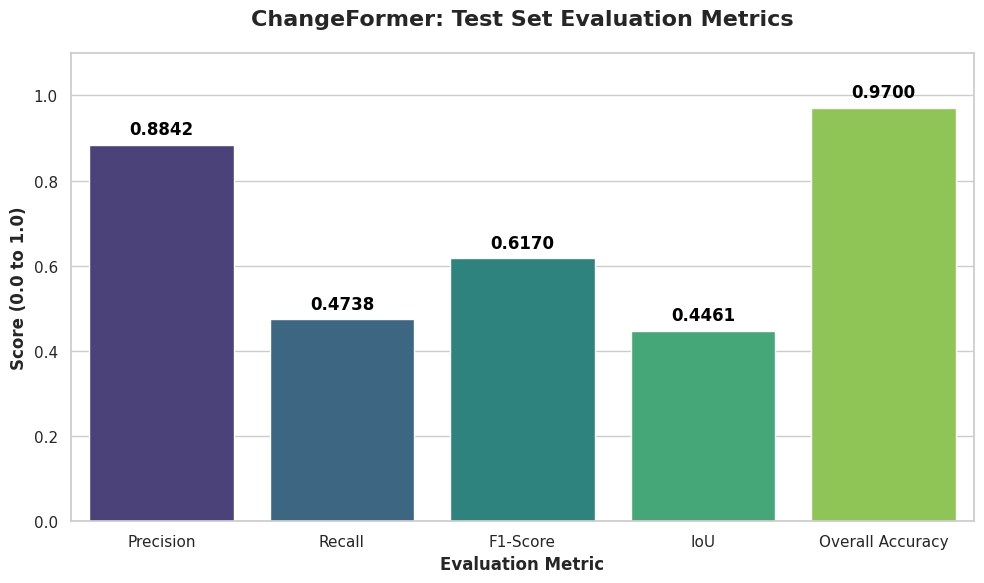

Chart saved to /content/test_metrics_chart.png (Ready for README.md)


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def evaluate_and_plot_metrics(model: nn.Module, model_path: str) -> None:
    """
    Loads the best weights, evaluates on the Test Set, and generates a publication-ready bar chart.
    """
    # 1. Load the Best Model Weights
    checkpoint = torch.load(model_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"Loaded Best Model from Epoch {checkpoint['epoch']} (Val F1: {checkpoint['val_f1']:.4f})")
    print("Evaluating on Test Set... Please wait.")

    # 2. Run Evaluation on Test Set
    test_loss, test_metrics = validate_epoch(model, test_loader, criterion, device)

    print("-" * 60)
    print("Test Set Results:")
    for k, v in test_metrics.items():
        print(f" - {k}: {v:.4f}")

    # 3. Generate High-Quality Bar Chart for README
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(10, 6))

    # Convert metrics dictionary to a DataFrame for Seaborn
    df_metrics = pd.DataFrame({
        'Metric': list(test_metrics.keys()),
        'Score': list(test_metrics.values())
    })

    # Create Bar Plot
    ax = sns.barplot(x='Metric', y='Score', data=df_metrics, palette="viridis", hue='Metric', dodge=False, legend=False)

    # Add data labels on top of each bar
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.4f}",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=12, fontweight='bold', color='black', xytext=(0, 5),
                    textcoords='offset points')

    plt.ylim(0, 1.1)
    plt.title("ChangeFormer: Test Set Evaluation Metrics", fontsize=16, fontweight='bold', pad=20)
    plt.ylabel("Score (0.0 to 1.0)", fontsize=12, fontweight='bold')
    plt.xlabel("Evaluation Metric", fontsize=12, fontweight='bold')

    # Save the chart as a high-resolution image
    chart_path = "/content/test_metrics_chart.png"
    plt.tight_layout()
    plt.savefig(chart_path, dpi=300)
    plt.show()

    print(f"Chart saved to {chart_path} (Ready for README.md)")

# Run Test Evaluation & Plotting
evaluate_and_plot_metrics(model, "/content/changeformer_best_weights.pth")

Searching randomly for patches with actual changes...


/tmp/ipykernel_480/1253263909.py:62: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pre_patch = Image.fromarray(pre_np, mode="RGB")
/tmp/ipykernel_480/1253263909.py:63: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  post_patch = Image.fromarray(post_np, mode="RGB")
/tmp/ipykernel_480/1253263909.py:64: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  label_patch = Image.fromarray(lbl_np, mode="L")


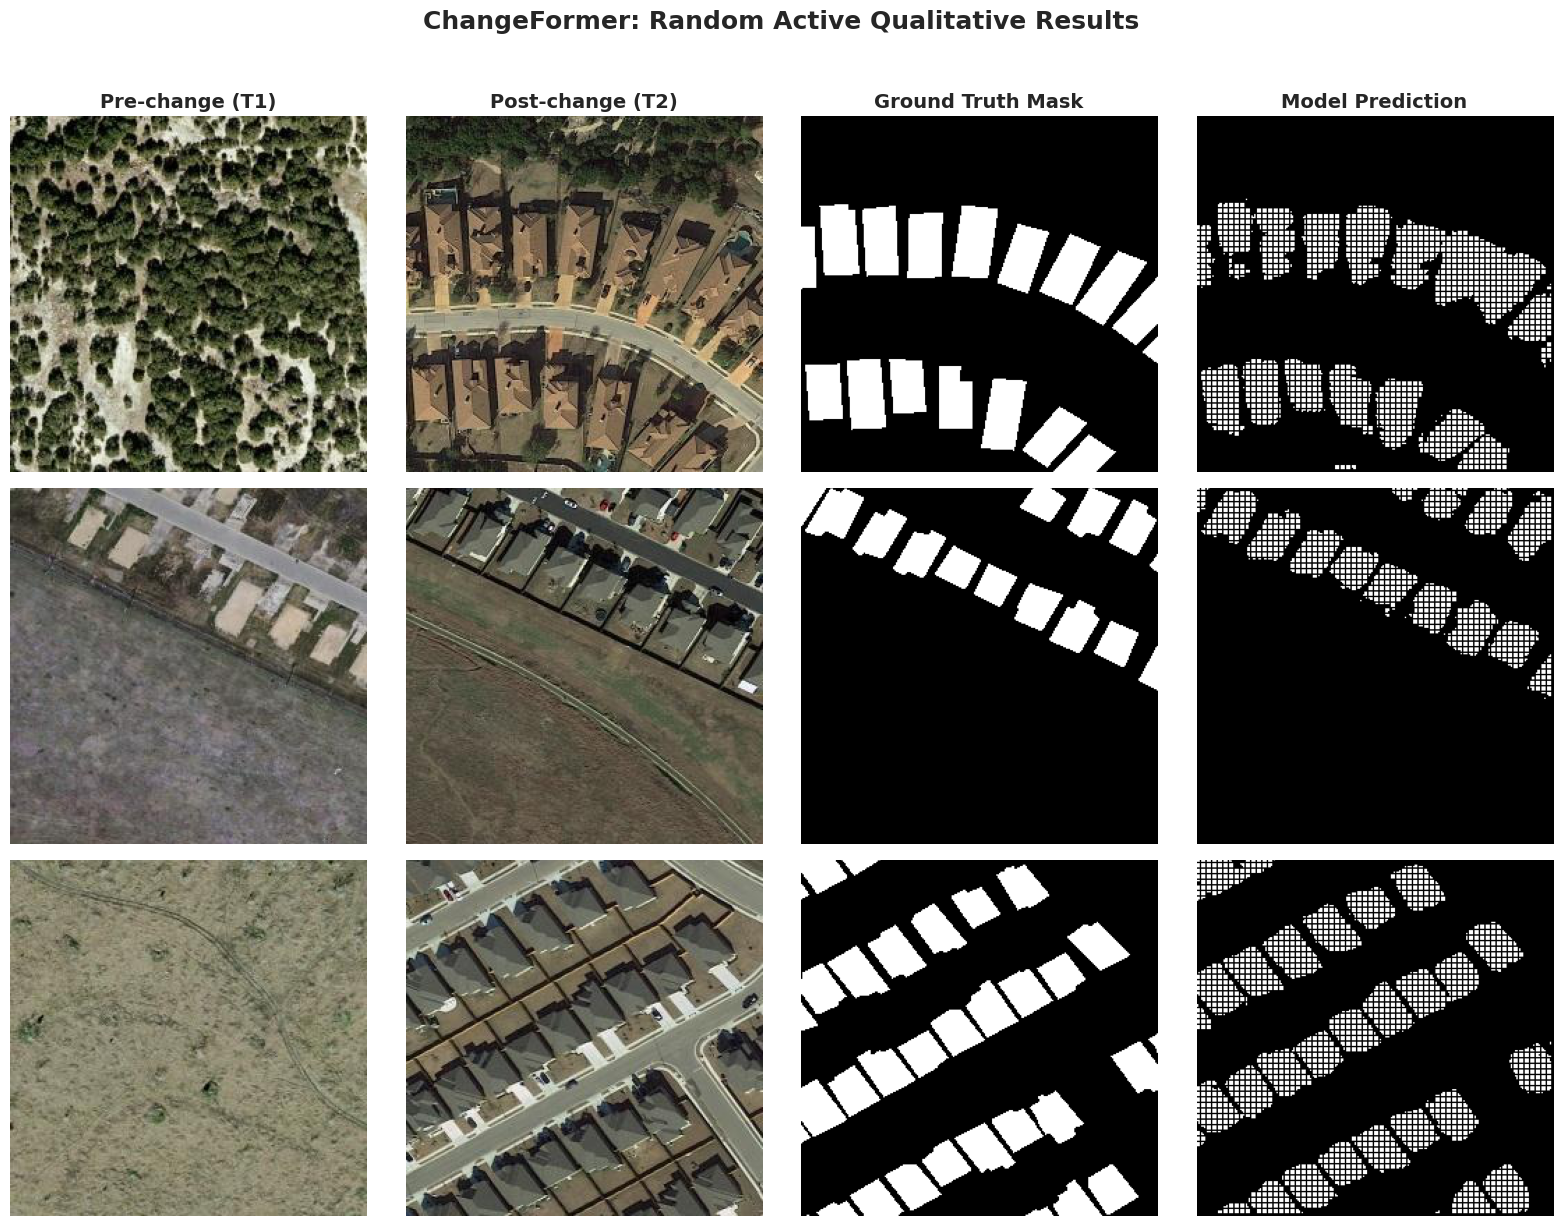

Random active visual results successfully saved to: /content/random_active_visual_inference.png (Ready for README.md)


In [31]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch

def visualize_random_active_predictions(model: nn.Module, dataloader: DataLoader, num_samples: int = 3) -> None:
    """
    Randomly samples the dataset to find patches that contain changes (active pixels),
    runs inference, and plots them. Ensures different results on every execution.
    """
    model.eval()
    dataset = dataloader.dataset

    # Shuffle all dataset indices to guarantee different images on each run
    all_indices = list(range(len(dataset)))
    random.shuffle(all_indices)

    selected_pre = []
    selected_post = []
    selected_targets = []
    selected_preds = []

    print("Searching randomly for patches with actual changes...")

    with torch.no_grad():
        for idx in all_indices:
            sample = dataset[idx]
            target = sample['label']

            # Find patches with at least 100 pixels of change
            if target.sum() > 100:
                s_pre = sample['pre_image'].unsqueeze(0).to(device)   # Add batch dim
                s_post = sample['post_image'].unsqueeze(0).to(device)
                s_target = target.to(device)

                # Forward pass
                with torch.amp.autocast('cuda', enabled=(device == "cuda")):
                    logits = model(s_pre, s_post)

                s_pred = torch.argmax(logits, dim=1).squeeze(0)

                selected_pre.append(s_pre.squeeze(0))
                selected_post.append(s_post.squeeze(0))
                selected_targets.append(s_target)
                selected_preds.append(s_pred)

            if len(selected_pre) >= num_samples:
                break

    if len(selected_pre) < num_samples:
        print(f"Warning: Only found {len(selected_pre)} active patches.")

    # Helper function to Denormalize ImageNet tensors back to [0, 1] RGB
    def denorm_img(tensor_img: torch.Tensor) -> np.ndarray:
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1).to(tensor_img.device)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1).to(tensor_img.device)
        tensor_img = tensor_img * std + mean
        tensor_img = tensor_img.clamp(0, 1)
        return tensor_img.permute(1, 2, 0).cpu().numpy()

    # Plotting Grid
    fig, axes = plt.subplots(nrows=len(selected_pre), ncols=4, figsize=(16, 4 * len(selected_pre)))
    fig.suptitle("ChangeFormer: Random Active Qualitative Results", fontsize=18, fontweight='bold', y=1.02)
    col_titles = ["Pre-change (T1)", "Post-change (T2)", "Ground Truth Mask", "Model Prediction"]

    for i in range(len(selected_pre)):
        ax_row = axes[i] if len(selected_pre) > 1 else axes

        # 1. Pre-change Image
        ax_row[0].imshow(denorm_img(selected_pre[i]))
        ax_row[0].axis('off')
        if i == 0: ax_row[0].set_title(col_titles[0], fontsize=14, fontweight='bold')

        # 2. Post-change Image
        ax_row[1].imshow(denorm_img(selected_post[i]))
        ax_row[1].axis('off')
        if i == 0: ax_row[1].set_title(col_titles[1], fontsize=14, fontweight='bold')

        # 3. Ground Truth Mask (Strict vmin=0, vmax=1)
        ax_row[2].imshow(selected_targets[i].cpu().numpy(), cmap='gray', vmin=0, vmax=1)
        ax_row[2].axis('off')
        if i == 0: ax_row[2].set_title(col_titles[2], fontsize=14, fontweight='bold')

        # 4. Model Prediction (Strict vmin=0, vmax=1)
        ax_row[3].imshow(selected_preds[i].cpu().numpy(), cmap='gray', vmin=0, vmax=1)
        ax_row[3].axis('off')
        if i == 0: ax_row[3].set_title(col_titles[3], fontsize=14, fontweight='bold')

    plt.tight_layout()
    save_path = "/content/random_active_visual_inference.png"
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Random active visual results successfully saved to: {save_path} (Ready for README.md)")

# Run Intelligent Random Visual Inference
visualize_random_active_predictions(model, test_loader, num_samples=3)